# Quasinormal modes with Leaver's method

From the course [*Black-hole perturbation theory*](https://svykho.github.io/lab/course/) by Alejandro Svyatkovskyy Kholyavka, [Lesson 12: Compute it yourself](https://svykho.github.io/lab/course/compute.html).

This notebook computes the quasinormal frequencies of a Schwarzschild black hole to six digits and more, with the continued fraction of Leaver (1985). It reproduces the table and the spectrum of [Lesson 6](https://svykho.github.io/lab/course/quasinormal-modes.html). It needs only NumPy and Matplotlib and runs in a few seconds.

Units: $G = c = M = 1$. Inside the continued fraction we follow Leaver and use $2M = 1$, so the frequencies come out as $2M\omega$; we divide by two at the end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## The continued fraction

Leaver writes the solution as a prefactor that is ingoing at the horizon and outgoing at infinity, times a power series in $(r - 2M)/r$. The coefficients obey a three-term recurrence

$$\alpha_k a_{k+1} + \beta_k a_k + \gamma_k a_{k-1} = 0,$$

and the series converges at infinity only if $\omega$ is a quasinormal frequency. That condition is the vanishing of a continued fraction. With $\rho = -i\omega$ and $\varepsilon = s^2 - 1$ for a field of spin $s$ (0 scalar, 1 electromagnetic, 2 gravitational):

$$\alpha_k = k^2 + (2\rho + 2)k + 2\rho + 1, \quad \beta_k = -\left[2k^2 + (8\rho + 2)k + 8\rho^2 + 4\rho + \ell(\ell+1) - \varepsilon\right], \quad \gamma_k = k^2 + 4\rho k + 4\rho^2 - \varepsilon - 1.$$

For the overtone $n$ the fraction is "inverted" $n$ times (Leaver 1985, Nollert 1993): the first $n$ levels are moved to the other side. Mathematically nothing changes, but the $n$-th zero becomes the most stable one, which keeps the root finder from jumping to a neighbour.

In [2]:
def leaver_cf(w, l, s=2, n=0, depth=3000):
    """Leaver's continued fraction, inverted n times. Zero at a quasinormal mode.
    w is 2M*omega (units 2M = 1)."""
    rho = -1j * w
    eps = s * s - 1

    def alpha(k):
        return k * k + (2 * rho + 2) * k + 2 * rho + 1

    def beta(k):
        return -(2 * k * k + (8 * rho + 2) * k + 8 * rho * rho + 4 * rho + l * (l + 1) - eps)

    def gamma(k):
        return k * k + 4 * rho * k + 4 * rho * rho - eps - 1

    # the infinite part, evaluated from the bottom up
    tail = 0j
    for k in range(depth, n, -1):
        tail = alpha(k - 1) * gamma(k) / (beta(k) - tail)
    # the n levels moved to the other side by the inversion
    head = 0j
    if n > 0:
        x = beta(0)
        for k in range(1, n):
            x = beta(k) - alpha(k - 1) * gamma(k) / x
        head = alpha(n - 1) * gamma(n) / x
    return beta(n) - tail - head

## Finding the zeros

Any root finder that works with complex numbers will do. The secant method is short and needs no derivative: draw the line through the last two points and see where it crosses zero.

In [3]:
def secant(f, x0, x1, tol=1e-12, maxit=60):
    f0, f1 = f(x0), f(x1)
    for _ in range(maxit):
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        if abs(x2 - x1) < tol * abs(x2):
            return x2
        x0, f0, x1, f1 = x1, f1, x2, f(x2)
    raise RuntimeError("the secant method did not converge")


def qnm(l, n, guess, s=2, depth=3000):
    """Quasinormal frequency M*omega of multipole l and overtone n, starting from a guess for M*omega."""
    f = lambda w: leaver_cf(w, l, s, n, depth)
    return secant(f, 2 * guess, 2 * guess * (1 + 1e-4)) / 2


# the fundamental l = 2 gravitational mode, starting from the light-ring estimate of Lesson 6
guess = (2 + 0.5) / np.sqrt(27) - 0.5j / np.sqrt(27)
w = qnm(2, 0, guess)
print(f"light-ring guess  M omega = {guess:.5f}")
print(f"Leaver            M omega = {w:.6f}")

light-ring guess  M omega = 0.48113-0.09623j
Leaver            M omega = 0.373672-0.088962j


## The ladder of overtones

Each overtone is found starting from the previous ones: the light-ring formula for $n = 0$, a step down for $n = 1$, and a straight-line extrapolation after that.

In [4]:
def ladder(l, nmax=7, s=2):
    ws = []
    for n in range(nmax + 1):
        if n == 0:
            g = (l + 0.5) / np.sqrt(27) - 0.5j / np.sqrt(27)
        elif n == 1:
            g = ws[0] - 0.19j
        else:
            g = 2 * ws[-1] - ws[-2]
        ws.append(qnm(l, n, g, s))
    return np.array(ws)


spectrum = {l: ladder(l) for l in (2, 3, 4)}
for l, ws in spectrum.items():
    print(f"l = {l}")
    for n, w in enumerate(ws):
        print(f"   n = {n}   M omega = {w.real:.6f} {w.imag:+.6f} i")

l = 2
   n = 0   M omega = 0.373672 -0.088962 i
   n = 1   M omega = 0.346711 -0.273915 i
   n = 2   M omega = 0.301053 -0.478277 i
   n = 3   M omega = 0.251505 -0.705148 i
   n = 4   M omega = 0.207515 -0.946845 i
   n = 5   M omega = 0.169299 -1.195608 i
   n = 6   M omega = 0.133252 -1.447911 i
   n = 7   M omega = 0.092822 -1.703841 i
l = 3
   n = 0   M omega = 0.599443 -0.092703 i
   n = 1   M omega = 0.582644 -0.281298 i
   n = 2   M omega = 0.551685 -0.479093 i
   n = 3   M omega = 0.511962 -0.690337 i
   n = 4   M omega = 0.470174 -0.915649 i
   n = 5   M omega = 0.431386 -1.152151 i
   n = 6   M omega = 0.397660 -1.395912 i
   n = 7   M omega = 0.368992 -1.643845 i
l = 4
   n = 0   M omega = 0.809178 -0.094164 i
   n = 1   M omega = 0.796632 -0.284334 i
   n = 2   M omega = 0.772710 -0.479908 i
   n = 3   M omega = 0.739837 -0.683924 i
   n = 4   M omega = 0.701516 -0.898239 i
   n = 5   M omega = 0.661572 -1.122977 i
   n = 6   M omega = 0.623109 -1.356686 i
   n = 7   M ome

The values in Lesson 6 were computed with 30 digits and depth 4000. Ordinary double precision with depth 3000 agrees with them to the six decimals shown there:

In [5]:
course = {  # Lesson 6, rounded to six decimals
    2: [0.373672 - 0.088962j, 0.346711 - 0.273915j, 0.301053 - 0.478277j, 0.251505 - 0.705148j,
        0.207515 - 0.946845j, 0.169299 - 1.195608j, 0.133252 - 1.447911j, 0.092822 - 1.703841j],
    3: [0.599443 - 0.092703j, 0.582644 - 0.281298j, 0.551685 - 0.479093j, 0.511962 - 0.690337j,
        0.470174 - 0.915649j, 0.431386 - 1.152151j, 0.397660 - 1.395912j, 0.368992 - 1.643845j],
    4: [0.809178 - 0.094164j, 0.796632 - 0.284334j, 0.772710 - 0.479908j, 0.739837 - 0.683924j,
        0.701516 - 0.898239j, 0.661572 - 1.122977j, 0.623109 - 1.356686j, 0.587909 - 1.597171j],
}
worst = max(abs(spectrum[l][n] - course[l][n]) for l in course for n in range(8))
print(f"largest difference with the table of Lesson 6: {worst:.1e}")

largest difference with the table of Lesson 6: 6.0e-07


## The spectrum

The same picture as in Lesson 6: higher means slower decay, further right means higher pitch.

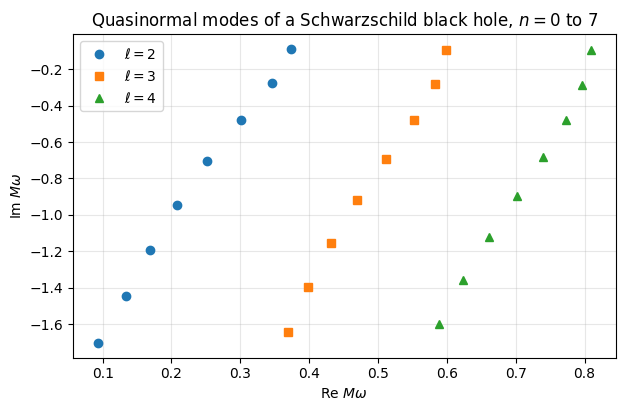

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for l, mk in zip((2, 3, 4), ("o", "s", "^")):
    ws = spectrum[l]
    ax.plot(ws.real, ws.imag, mk, label=f"$\\ell = {l}$", ms=6)
ax.set_xlabel(r"Re $M\omega$")
ax.set_ylabel(r"Im $M\omega$")
ax.set_title("Quasinormal modes of a Schwarzschild black hole, $n = 0$ to $7$")
ax.legend()
plt.show()

## Other fields

The same function handles a scalar field ($s = 0$) and the electromagnetic field ($s = 1$). These are the fundamental modes quoted in Lessons 3 and 4.

In [7]:
print("scalar          l = 0:", f"{qnm(0, 0, 0.11 - 0.10j, s=0):.5f}")
print("scalar          l = 2:", f"{qnm(2, 0, 0.48 - 0.10j, s=0):.5f}")
print("electromagnetic l = 2:", f"{qnm(2, 0, 0.46 - 0.10j, s=1):.5f}")

scalar          l = 0: 0.11045-0.10490j
scalar          l = 2: 0.48364-0.09676j
electromagnetic l = 2: 0.45760-0.09500j


## How deep is deep enough?

The continued fraction has to be cut somewhere. The faster a mode decays, the deeper one has to go. Here is the error of three $\ell = 2$ modes against the depth, measured against a run at depth 20 000.

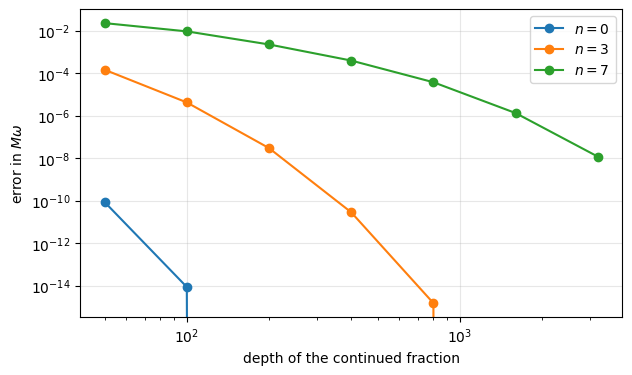

In [8]:
depths = [50, 100, 200, 400, 800, 1600, 3200]
fig, ax = plt.subplots(figsize=(7, 4))
for n in (0, 3, 7):
    exact = qnm(2, n, spectrum[2][n], depth=20000)
    errs = [abs(qnm(2, n, spectrum[2][n], depth=d) - exact) for d in depths]
    ax.loglog(depths, errs, "o-", label=f"$n = {n}$")
ax.set_xlabel("depth of the continued fraction")
ax.set_ylabel(r"error in $M\omega$")
ax.legend()
plt.show()

## Try this

- Find the $\ell = 2$ overtones up to $n = 15$ (use a depth of 6000). The real part almost vanishes at $n = 8$, near $M\omega = -2i$, and then grows again. Past that point the root finder may return the mirror modes, with a negative real part: they are the same modes turning the other way.
- For very high overtones the real part tends to $\ln 3/(8\pi) \approx 0.0437$ (Nollert 1993, Motl 2003). It gets there slowly: compare with what you find at $n = 15$.
- Start the root finder far from any mode. Which zero does it find? The figure in Lesson 12 shows why the inversion matters.